# Project 2: Credit Card Fraud Detection
**Student Name:** Nabyonga Theresa  
**Registration Number:** S25m19/040   
**Access Number:** B35752  

## 1. Introduction

Credit card fraud is a major challenge for financial institutions, leading to financial losses for customers and card providers. This project applies anomaly detection techniques to identify suspicious transactions.

The dataset contains 284,807 transactions recorded over two days in September 2013, of which only 492 are fraudulent. This makes it a highly imbalanced dataset.

The aim is to explore and prepare the data, apply different detection techniques and evaluate their ability to identify and rank fraudulent transactions.

In [1]:
# Import pandas for loading and manipulating datasets
import pandas as pd
# Import numpy for numerical operations
import numpy as np
# Import matplotlib and seaborn for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# Import pathlib to handle file paths
from pathlib import Path
# Import libraries for data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Import evaluation metrics for assessing model performance
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Import warnings to suppress unnecessary warning messages
import warnings
warnings.filterwarnings('ignore')

# Set the default style for visualisations
sns.set_style('whitegrid')

# Display plots within the notebook
%matplotlib inline

In [2]:
# Print library versions for reproducibility
import sys
import sklearn
import pandas
import numpy

print('Python      :', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('pandas      :', pandas.__version__)
print('numpy       :', numpy.__version__)

# Set global random seed for full reproducibility
np.random.seed(42)

Python      : 3.12.10
scikit-learn: 1.9.1
pandas      : 3.1.1
numpy       : 2.5.4


## 2. Dataset Description

The Credit Card Fraud Detection dataset contains transaction details, including time, amount and anonymised numerical features. The `Class` variable identifies transactions as legitimate (0) or fraudulent (1).

In [3]:
# Checking the current notebook working directory
print("Current working directory:", Path.cwd())

possible_paths = [
    Path.cwd() / "creditcard.csv",
    Path.cwd().parent / "creditcard.csv"
]

# Select the first location where the dataset exists
data_path = next((path for path in possible_paths if path.exists()), None)

# Stop execution if the dataset cannot be located
if data_path is None:
    raise FileNotFoundError(
        "creditcard.csv was not found. Please check its location."
    )

# Load the dataset into a pandas DataFrame
df = pd.read_csv(data_path)

# Display confirmation and dataset dimensions
print("Dataset loaded successfully!")
print("Dataset location:", data_path)
print("Dataset shape:", df.shape)

# Display the first five records
display(df.head())

Current working directory: c:\Users\Tesa\Documents\Data mining Assignment 2-Nabyonga Theresa-B35752\Project_2_Credit_Card_Fraud
Dataset loaded successfully!
Dataset location: c:\Users\Tesa\Documents\Data mining Assignment 2-Nabyonga Theresa-B35752\creditcard.csv
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### 2.1 Dataset Structure
The dataset structure is examined to understand the number of observations, available variables, data types and memory usage. This helps establish the characteristics of the data before preprocessing.

In [4]:
# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display column names
print("\nDataset columns:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset information:")
df.info()

Dataset dimensions: (284807, 31)

Dataset columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14 

In [5]:
# Generate descriptive statistics for all numerical variables
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [6]:
# Counting missing values across the entire dataset
print("Total missing values:", df.isnull().sum().sum())

# Display missing values for each column
print("\nMissing values per column:")
print(df.isnull().sum())

# Counting duplicate records
print("\nNumber of duplicate records:", df.duplicated().sum())

Total missing values: 0

Missing values per column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Number of duplicate records: 1081


### 2.2 Class Distribution
The distribution of legitimate and fraudulent transactions is examined to establish the extent of class imbalance. This is particularly important because fraudulent transactions represent a very small proportion of the dataset, which can affect model training and evaluation.

In [7]:
# Counting the number of transactions in each class
class_counts = df['Class'].value_counts().sort_index()

# Calculate the percentage of each class
class_percentages = df['Class'].value_counts(normalize=True).sort_index() * 100

# Display transaction counts
print("Transaction counts:")
print(class_counts)

# Display percentage distribution
print("\nTransaction percentages:")
print(class_percentages.round(4))

Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Transaction percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


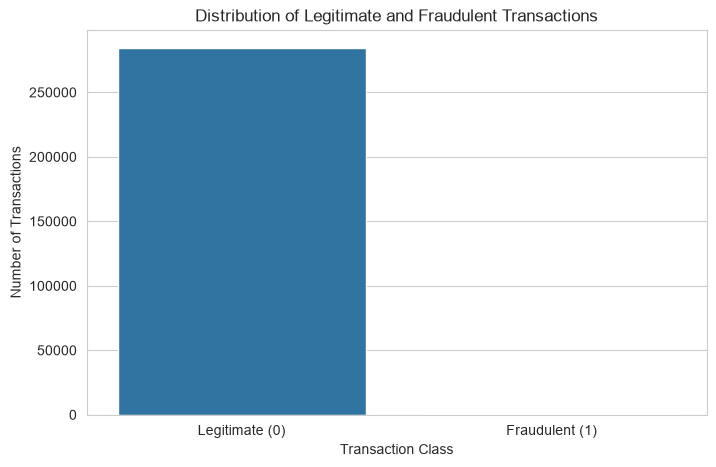

In [8]:
# Creating a figure for the class distribution
plt.figure(figsize=(8, 5))

# Plot the number of transactions in each class
sns.countplot(data=df, x='Class')

# Add chart labels and title
plt.title('Distribution of Legitimate and Fraudulent Transactions')
plt.xlabel('Transaction Class')
plt.ylabel('Number of Transactions')

# Replace numerical labels with descriptive labels
plt.xticks([0, 1], ['Legitimate (0)', 'Fraudulent (1)'])

# Display the chart
plt.show()

### 2.3 Summary of Dataset Exploration

The dataset contains 284,807 transactions and 31 columns, including 30 numerical features and the target variable `Class`. Features V1–V28 are anonymised PCA variables, while `Time` and `Amount` represent transaction time and value.

There are no missing values, but 1,081 duplicate records were identified for further investigation.

The dataset is highly imbalanced, with 284,315 legitimate transactions (99.8273%) and only 492 fraudulent transactions (0.1727%). Therefore, evaluation should focus on detecting fraud rather than accuracy alone.

### 2.4 Duplicate Record Investigation

Duplicate records are investigated to determine whether they occur among legitimate or fraudulent transactions. This helps establish whether removing duplicates could affect the representation of either class.

In [9]:
# Identify all records that belong to duplicate groups
duplicate_records = df[df.duplicated(keep=False)]

# Count duplicate records by transaction class
print("Duplicate records by class:")
print(duplicate_records['Class'].value_counts())

# Calculate the percentage of duplicate records by class
print("\nDuplicate record percentages:")
print(
    duplicate_records['Class']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Display a sample of duplicate records
display(duplicate_records.head(10))

Duplicate records by class:
Class
0    1822
1      32
Name: count, dtype: int64

Duplicate record percentages:
Class
0    98.27
1     1.73
Name: proportion, dtype: float64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


### 2.5 Transaction Amount Analysis

Transaction amounts are examined to understand differences between legitimate and fraudulent transactions. This may help identify unusual transaction values and determine whether transaction amount provides useful information for fraud detection.

In [10]:
# Compare transaction amounts for legitimate and fraudulent transactions
amount_summary = df.groupby('Class')['Amount'].describe()

# Display the descriptive statistics
display(amount_summary)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


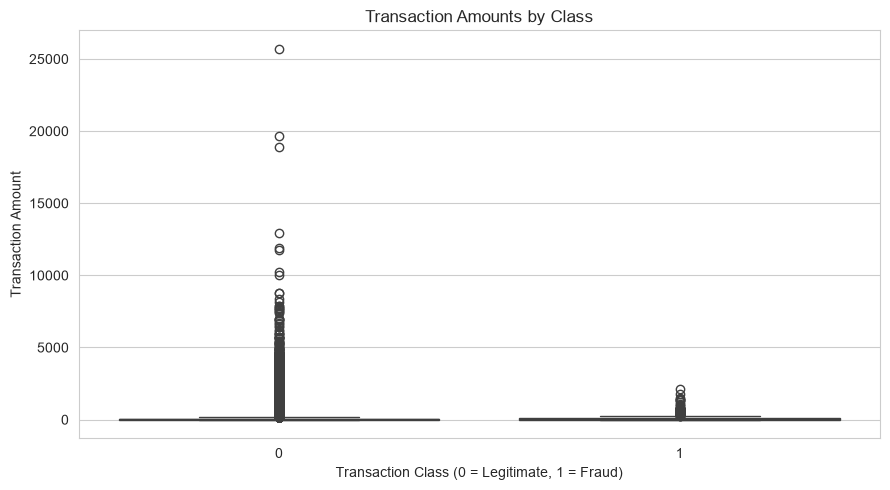

In [11]:
# Creating a boxplot to compare transaction amounts by class
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Class', y='Amount')

# Add chart labels and title
plt.title('Transaction Amounts by Class')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Transaction Amount')

# Improve the layout
plt.tight_layout()

# Display the plot
plt.show()

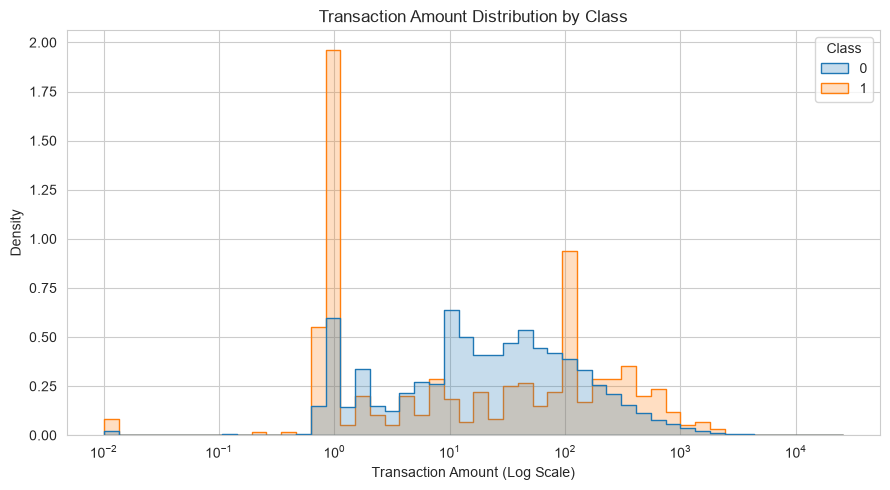

In [12]:
# Creating a figure for the transaction amount distribution
plt.figure(figsize=(9, 5))

# Use a logarithmic scale to make the distribution easier to examine
sns.histplot(
    data=df,
    x='Amount',
    hue='Class',
    bins=50,
    log_scale=(True, False),
    element='step',
    stat='density',
    common_norm=False
)

# Add chart labels and title
plt.title('Transaction Amount Distribution by Class')
plt.xlabel('Transaction Amount (Log Scale)')
plt.ylabel('Density')

# Display the plot
plt.tight_layout()
plt.show()

### 2.6 Summary of Transaction Amount Analysis

Fraudulent transactions had a higher average amount (122.21) than legitimate transactions (88.29), but a lower median (9.25 compared to 22.00).

This suggests that transaction amount alone cannot reliably identify fraud, as suspicious transactions can involve both small and large amounts. Other transaction characteristics must also be considered.

In [13]:
# Identify duplicate rows, keeping the first occurrence of each record
excess_duplicates = df[df.duplicated(keep='first')]

# Count excess duplicate rows by transaction class
print("Excess duplicate rows by class:")
print(excess_duplicates['Class'].value_counts())

# Display the total number of excess duplicate rows
print("\nTotal excess duplicate rows:", len(excess_duplicates))

Excess duplicate rows by class:
Class
0    1062
1      19
Name: count, dtype: int64

Total excess duplicate rows: 1081


### 2.7 Handling Duplicate Records

The dataset contained 1,081 duplicate records (1,062 legitimate and 19 fraudulent), which were removed to reduce repeated observations. After removal, the dataset contained 283,726 transactions, including 473 fraudulent cases. The dataset remained highly imbalanced, and it is acknowledged that some identical records may represent genuine repeated transactions.

In [14]:
# Create a cleaned copy of the original dataset
# The original df is retained for reference
df_clean = df.drop_duplicates().copy()

# Compare the dataset dimensions before and after duplicate removal
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Check the number of duplicate records remaining
print("\nRemaining duplicate records:", df_clean.duplicated().sum())

# Examine the class distribution after duplicate removal
print("\nClass distribution after cleaning:")
print(df_clean['Class'].value_counts())

# Calculate the new class percentages
print("\nUpdated class percentages:")
print(
    (df_clean['Class'].value_counts(normalize=True) * 100).round(4)
)

Original dataset shape: (284807, 31)
Cleaned dataset shape: (283726, 31)

Remaining duplicate records: 0

Class distribution after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64

Updated class percentages:
Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64


### 2.8 Transaction Time Analysis

Transaction time is examined to explore how legitimate and fraudulent transactions are distributed over the observation period. The time variable represents elapsed seconds since the first transaction rather than actual clock time. It is therefore converted into elapsed hours to make the transaction patterns easier to examine.

In [15]:
# Convert transaction time from seconds into elapsed hours
# This preserves the full observation period of approximately 48 hours
df_clean['Elapsed_Hour'] = (df_clean['Time'] // 3600).astype(int)

# Count transactions for each hour and transaction class
hourly_transactions = (
    df_clean.groupby(['Elapsed_Hour', 'Class'])
    .size()
    .reset_index(name='Count')
)

# Display the first 10 observations
display(hourly_transactions.head(10))

,Elapsed_Hour,Class,Count
0,0,0,3929
1,0,1,2
2,1,0,2211
3,1,1,2
4,2,0,1552
5,2,1,21
6,3,0,1805
7,3,1,13
8,4,0,1076
9,4,1,6


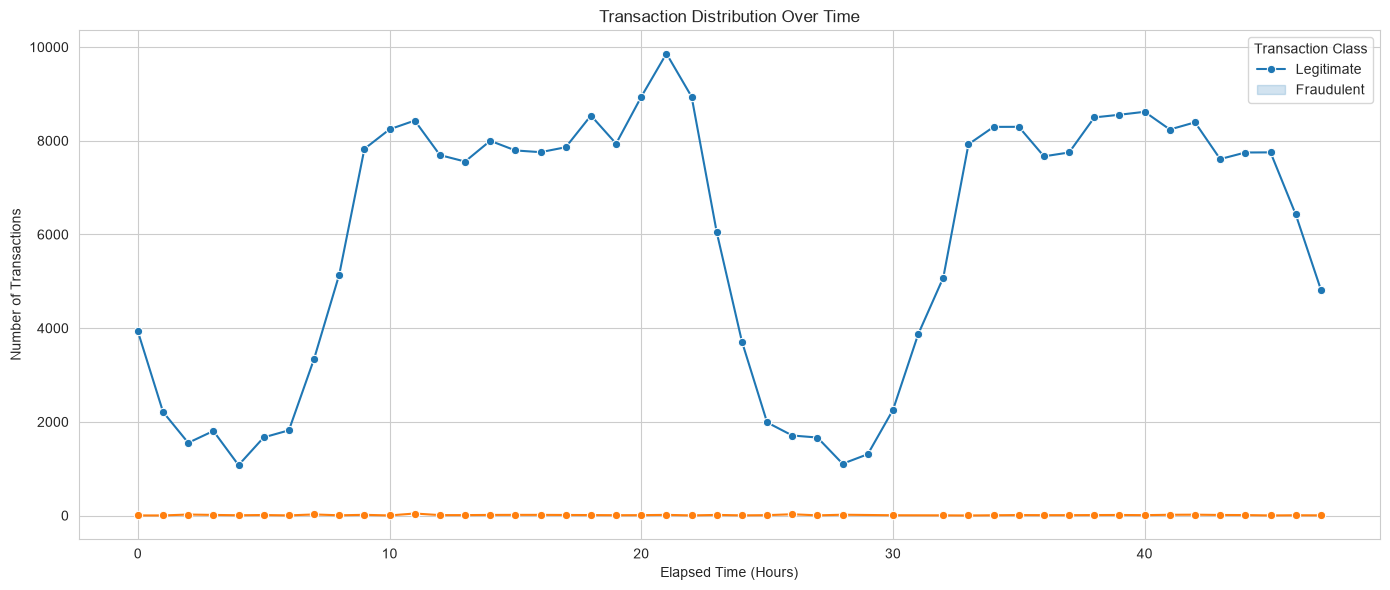

In [16]:
# Creating a figure for transaction patterns over the observation period
plt.figure(figsize=(14, 6))

# Plot the number of transactions for each class over time
sns.lineplot(
    data=hourly_transactions,
    x='Elapsed_Hour',
    y='Count',
    hue='Class',
    marker='o'
)

# Add chart title and axis labels
plt.title('Transaction Distribution Over Time')
plt.xlabel('Elapsed Time (Hours)')
plt.ylabel('Number of Transactions')

# Improve legend labels
plt.legend(
    title='Transaction Class',
    labels=['Legitimate', 'Fraudulent']
)

# Display the chart
plt.tight_layout()
plt.show()

In [17]:
# Calculate total transactions recorded in each hour
hourly_totals = df_clean.groupby('Elapsed_Hour').size()

# Calculate fraudulent transactions recorded in each hour
hourly_fraud = df_clean[df_clean['Class'] == 1].groupby('Elapsed_Hour').size()

# Calculate the percentage of fraudulent transactions per hour
hourly_fraud_rate = (
    (hourly_fraud / hourly_totals) * 100
).fillna(0)

# Convert the results into a DataFrame
hourly_fraud_rate = hourly_fraud_rate.reset_index(name='Fraud_Percentage')

# Display the hourly fraud percentages
display(hourly_fraud_rate.head(10))

,Elapsed_Hour,Fraud_Percentage
0,0,0.050878
1,1,0.090375
2,2,1.335029
3,3,0.715072
4,4,0.554529
5,5,0.655152
6,6,0.164654
7,7,0.683304
8,8,0.097125
9,9,0.191302


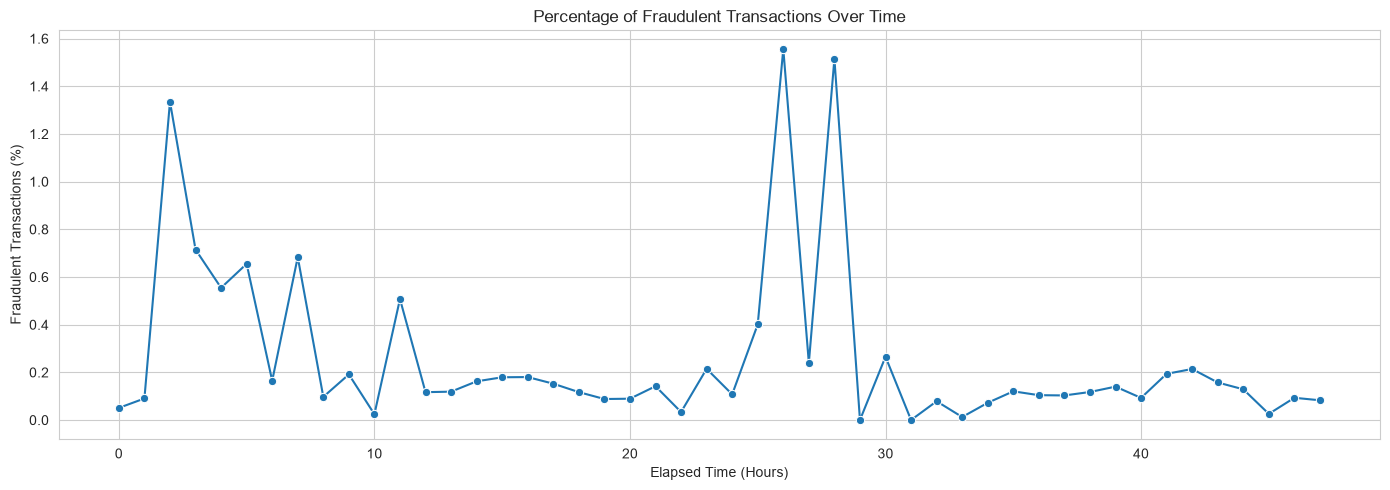

In [18]:
# Plot the percentage of fraudulent transactions over time
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=hourly_fraud_rate,
    x='Elapsed_Hour',
    y='Fraud_Percentage',
    marker='o'
)

# Add chart labels
plt.title('Percentage of Fraudulent Transactions Over Time')
plt.xlabel('Elapsed Time (Hours)')
plt.ylabel('Fraudulent Transactions (%)')

plt.tight_layout()
plt.show()

### 2.9 Transaction cleaning and Time Analysis Summary
The dataset contained 1,081 duplicate records, which were removed, leaving 283,726 transactions and 473 fraudulent cases (0.1667%).

Time analysis showed variations in fraud rates, with the second hour recording a higher rate of approximately 1.34%. However, since the dataset covers only two days, these patterns should be interpreted cautiously.

In [19]:
# Display all columns in the cleaned dataset
print("Columns in cleaned dataset:")
print(df_clean.columns.tolist())

# Check the dataset dimensions
print("\nDataset shape:", df_clean.shape)

# Confirm the target class distribution
print("\nTarget class distribution:")
print(df_clean['Class'].value_counts())

Columns in cleaned dataset:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'Elapsed_Hour']

Dataset shape: (283726, 32)

Target class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


## 3. Data Preparation 
The derived `Elapsed_Hour` column was excluded from modelling to avoid redundancy with the original `Time` feature. The remaining 30 numerical features (`Time`, `V1`–`V28`, and `Amount`) were used as input variables, while `Class` was kept separately as the target. This allows unsupervised models to detect unusual transaction patterns without using fraud labels during training.

In [20]:
# Select the original transaction features for modelling
# Exclude the target variable and the two additional time-analysis columns
feature_columns = [
    'Time',
    'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7',
    'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14',
    'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
    'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28',
    'Amount'
]

# Create the feature matrix
X = df_clean[feature_columns].copy()

# Create the target variable separately
y = df_clean['Class'].copy()

# Check the dimensions
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

# Confirm that all selected features are numerical
print("\nFeature data types:")
print(X.dtypes.value_counts())

Feature matrix shape: (283726, 30)
Target variable shape: (283726,)

Feature data types:
float64    30
Name: count, dtype: int64


### 3.1 Training and Testing split
The cleaned dataset was split into 70% training and 30% testing sets using stratified sampling to preserve the class distribution. Models will be trained on the training data and evaluated on unseen test data.
For unsupervised methods, fraud labels will only be used for evaluation, not during model training.

In [21]:
# Split the dataset into training and testing sets
# Stratification preserves the original class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Display the dimensions of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Display the percentage of fraud in each subset
print("\nFraud percentage in training set:",
      round(y_train.mean() * 100, 4), "%")

print("Fraud percentage in testing set:",
      round(y_test.mean() * 100, 4), "%")

Training features: (198608, 30)
Testing features: (85118, 30)

Training target distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Testing target distribution:
Class
0    84976
1      142
Name: count, dtype: int64

Fraud percentage in training set: 0.1667 %
Fraud percentage in testing set: 0.1668 %


## 4. Statistical Outlier Baseline 
The Robust Z-score method was selected to identify unusual transactions. It uses the median and Median Absolute Deviation (MAD), making it less sensitive to extreme values than the conventional Z-score.

The median and MAD will be calculated using training data only. Each test transaction will receive an anomaly score based on its highest absolute Robust Z-score across the features, with higher scores indicating more unusual transactions.

Fraud labels will only be used to evaluate how well the method ranks fraudulent transactions, not to calculate anomaly scores.

In [22]:
# Calculating the median of each feature using training data only
train_median = X_train.median()

# Calculating the Median Absolute Deviation (MAD)
train_mad = X_train.sub(train_median).abs().median()

# Identify features with zero MAD
print("Features with zero MAD:")
print(train_mad[train_mad == 0])

# Replace zero MAD values to avoid division by zero
# The small constant allows the calculation to proceed safely
train_mad = train_mad.replace(0, 1e-10)

# Calculate Robust Z-scores for the testing data
robust_z_scores = (
    0.6745 * (X_test - train_median) / train_mad
)

# Use the maximum absolute Robust Z-score as the anomaly score
statistical_scores = robust_z_scores.abs().max(axis=1)

# Display the highest anomaly scores
print("\nTop 10 transactions with the highest statistical anomaly scores:")
print(statistical_scores.sort_values(ascending=False).head(10))

Features with zero MAD:
Series([], dtype: float64)

Top 10 transactions with the highest statistical anomaly scores:
274771    852.896279
58465     652.386036
54018     394.599446
284249    338.159080
245474    291.228500
228158    271.149665
19760     261.072701
57209     252.994650
218985    249.851413
23128     246.111759
dtype: float64


In [23]:
# Import evaluation metrics
from sklearn.metrics import average_precision_score, roc_auc_score

# Calculate Average Precision and ROC-AUC
statistical_ap = average_precision_score(
    y_test, statistical_scores
)

statistical_roc = roc_auc_score(
    y_test, statistical_scores
)

# Display the evaluation results
print("STATISTICAL OUTLIER BASELINE")
print(f"Average Precision (PR-AUC): {statistical_ap:.4f}")
print(f"ROC-AUC: {statistical_roc:.4f}")

STATISTICAL OUTLIER BASELINE
Average Precision (PR-AUC): 0.0129
ROC-AUC: 0.8985


In [24]:
# Combining anomaly scores and actual fraud labels
statistical_results = pd.DataFrame({
    'Anomaly_Score': statistical_scores,
    'Actual_Class': y_test
})

# Sort transactions from highest to lowest anomaly score
statistical_results = statistical_results.sort_values(
    by='Anomaly_Score',
    ascending=False
)

# Evaluate the top-ranked transactions
k_values = [50, 100, 200, 500]

for k in k_values:

    # Select the top K suspicious transactions
    top_k = statistical_results.head(k)

    # Count fraudulent transactions among the top K
    fraud_found = top_k['Actual_Class'].sum()

    # Calculate precision and recall
    precision_k = fraud_found / k
    recall_k = fraud_found / y_test.sum()

    print(f"\nTop {k} transactions")
    print("Fraudulent transactions found:", int(fraud_found))
    print(f"Precision@{k}: {precision_k:.4f}")
    print(f"Recall@{k}: {recall_k:.4f}")


Top 50 transactions
Fraudulent transactions found: 0
Precision@50: 0.0000
Recall@50: 0.0000

Top 100 transactions
Fraudulent transactions found: 0
Precision@100: 0.0000
Recall@100: 0.0000

Top 200 transactions
Fraudulent transactions found: 0
Precision@200: 0.0000
Recall@200: 0.0000

Top 500 transactions
Fraudulent transactions found: 4
Precision@500: 0.0080
Recall@500: 0.0282


### 4.1 Statistical Baseline Results
The Robust Z-score baseline achieved an Average Precision of 0.0129 and ROC-AUC of 0.8985, showing some ability to distinguish fraudulent from legitimate transactions. However, its performance in prioritising highly suspicious transactions was weak.

No fraud cases appeared in the top 50, 100 or 200 transactions. Among the top 500, only four were fraudulent, resulting in 0.80% precision and 2.82% recall.

Despite its relatively high ROC-AUC, the method was ineffective at identifying fraud within a small investigation list. It therefore provides a baseline for comparing the clustering-based and classification-based approaches.

## 5. Cluster-Based Anomaly Detection
K-Means was selected to group transactions based on similarities in their numerical features, assuming that unusual transactions may lie farther from their cluster centres. 
MiniBatchKMeans was used for efficiency, with eight clusters selected to capture different transaction patterns.

The distance between each transaction and its assigned cluster centre was used as the anomaly score, with larger distances indicating more unusual transactions. Features were standardised, and both the scaler and clustering model were fitted using training data only, without using fraud labels.

In [25]:
# Standizing the features 
# Import MiniBatchKMeans for efficient clustering
from sklearn.cluster import MiniBatchKMeans

# Create a StandardScaler
scaler = StandardScaler()

# Fit the scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_scaled = scaler.transform(X_test)

# Check the resulting dimensions
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (198608, 30)
Scaled testing data: (85118, 30)


k =  2 | inertia =   5681579.92 | silhouette = 0.0673
k =  4 | inertia =   5323355.98 | silhouette = 0.0682
k =  6 | inertia =   5088238.46 | silhouette = 0.0651
k =  8 | inertia =   4795767.88 | silhouette = 0.0727
k = 10 | inertia =   4628675.25 | silhouette = 0.0578
k = 12 | inertia =   4401659.47 | silhouette = 0.0692
k = 15 | inertia =   4140698.11 | silhouette = 0.0643


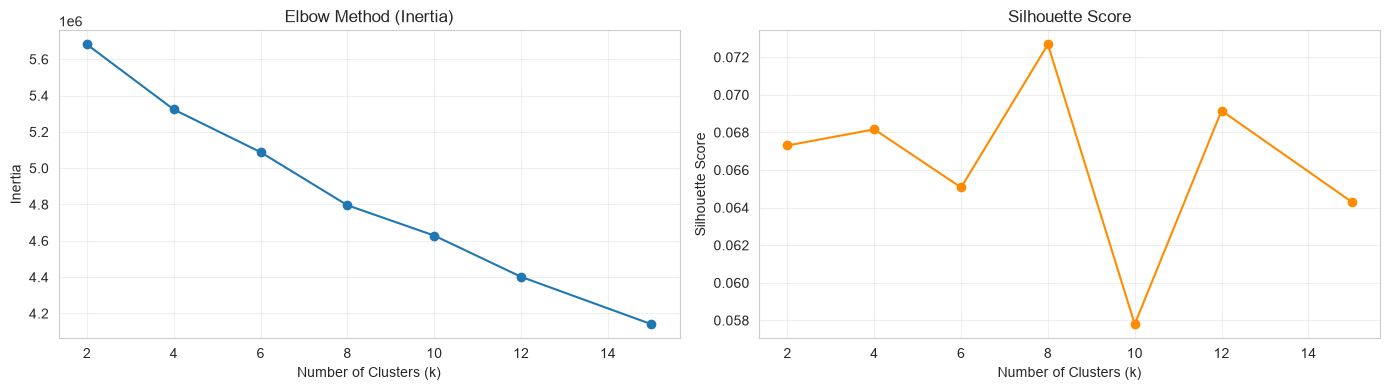

In [26]:
# Import silhouette metric
from sklearn.metrics import silhouette_score

# Import KMeans (full batch) for the k-selection sweep
from sklearn.cluster import KMeans

# Define the range of candidate cluster counts
k_candidates = [2, 4, 6, 8, 10, 12, 15]

# Store inertia and silhouette scores
inertia_values = []
silhouette_values = []

# Sample a subset of the training data for silhouette scoring
# (silhouette is O(n^2), so a large sample is impractical)
rng = np.random.RandomState(42)
sample_size = 5000
sample_idx = rng.choice(X_train_scaled.shape[0], size=sample_size, replace=False)
X_sample = X_train_scaled[sample_idx]

# Fit KMeans for each k and record diagnostics
for k in k_candidates:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_full = km.fit_predict(X_train_scaled)
    inertia_values.append(km.inertia_)
    # Compute silhouette on the sampled subset using the full-model labels
    silhouette_values.append(
        silhouette_score(X_sample, labels_full[sample_idx])
    )
    print(f'k = {k:2d} | inertia = {km.inertia_:12.2f} | silhouette = {silhouette_values[-1]:.4f}')

# Plot the elbow and silhouette diagnostics
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(k_candidates, inertia_values, marker='o')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(alpha=0.3)

axes[1].plot(k_candidates, silhouette_values, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [27]:
# Set a random seed for reproducibility
random_state = 42

# Initialise the MiniBatchKMeans model
kmeans = MiniBatchKMeans(
    n_clusters=8,
    random_state=random_state,
    batch_size=2048,
    n_init=10
)

# Fit the clustering model using training data only
kmeans.fit(X_train_scaled)

# Assign each training transaction to a cluster
train_clusters = kmeans.predict(X_train_scaled)

# Assign each testing transaction to a cluster
test_clusters = kmeans.predict(X_test_scaled)

# Display the number of transactions in each training cluster
print("Training cluster distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())

# Display the number of transactions in each testing cluster
print("\nTesting cluster distribution:")
print(pd.Series(test_clusters).value_counts().sort_index())

Training cluster distribution:
0    20782
1    51995
2    48229
3    26811
4     2911
5    23168
6    11643
7    13069
Name: count, dtype: int64

Testing cluster distribution:
0     8885
1    22169
2    20699
3    11606
4     1285
5     9865
6     4873
7     5736
Name: count, dtype: int64


In [28]:
# Retrieve the cluster centres
cluster_centres = kmeans.cluster_centers_

# Get the assigned cluster centre for each testing transaction
assigned_centres = cluster_centres[test_clusters]

# Calculate the distance from each transaction to its assigned centre
kmeans_scores = np.linalg.norm(
    X_test_scaled - assigned_centres,
    axis=1
)

# Display the highest anomaly scores
print("Top 10 transactions with the highest K-Means anomaly scores:")
print(
    pd.Series(kmeans_scores, index=X_test.index)
    .sort_values(ascending=False)
    .head(10)
)

Top 10 transactions with the highest K-Means anomaly scores:
274771    218.812379
58465     110.580193
220090     81.321110
91896      79.924339
23128      72.351243
233904     67.530485
195218     66.083224
219776     65.528892
284249     64.485732
54018      63.925854
dtype: float64


In [29]:
# Calculating Average Precision and ROC-AUC
kmeans_ap = average_precision_score(
    y_test,
    kmeans_scores
)

kmeans_roc = roc_auc_score(
    y_test,
    kmeans_scores
)

# Display the evaluation results
print("K-MEANS CLUSTERING RESULTS")
print("--------------------------------")
print(f"Average Precision (PR-AUC): {kmeans_ap:.4f}")
print(f"ROC-AUC: {kmeans_roc:.4f}")

K-MEANS CLUSTERING RESULTS
--------------------------------
Average Precision (PR-AUC): 0.1156
ROC-AUC: 0.9475


In [30]:
# Combining K-Means anomaly scores with actual fraud labels
kmeans_results = pd.DataFrame({
    'Anomaly_Score': kmeans_scores,
    'Actual_Class': y_test.to_numpy()
}, index=y_test.index)

# Sort transactions from highest to lowest anomaly score
kmeans_results = kmeans_results.sort_values(
    by='Anomaly_Score',
    ascending=False
)

# Evaluate the top-ranked transactions
k_values = [50, 100, 200, 500]

for k in k_values:

    # Select the top K suspicious transactions
    top_k = kmeans_results.head(k)

    # Count fraudulent transactions
    fraud_found = top_k['Actual_Class'].sum()

    # Calculate precision and recall
    precision_k = fraud_found / k
    recall_k = fraud_found / y_test.sum()

    print(f"\nTop {k} transactions")
    print("Fraudulent transactions found:", int(fraud_found))
    print(f"Precision@{k}: {precision_k:.4f}")
    print(f"Recall@{k}: {recall_k:.4f}")


Top 50 transactions
Fraudulent transactions found: 16
Precision@50: 0.3200
Recall@50: 0.1127

Top 100 transactions
Fraudulent transactions found: 25
Precision@100: 0.2500
Recall@100: 0.1761

Top 200 transactions
Fraudulent transactions found: 34
Precision@200: 0.1700
Recall@200: 0.2394

Top 500 transactions
Fraudulent transactions found: 55
Precision@500: 0.1100
Recall@500: 0.3873


### 5.1 K-Means Results and Interpretation
MiniBatchKMeans formed eight clusters and achieved an Average Precision of 0.1156 and ROC-AUC of 0.9475, outperforming the statistical baseline (0.0129 and 0.8985, respectively).

Among the top 50 transactions, it identified 16 fraudulent cases (32.00% precision and 11.27% recall). In the top 500, it identified 55 fraud cases, achieving 11.00% precision and 38.73% recall.

These results show that K-Means was more effective than the statistical baseline in prioritising suspicious transactions. However, it still missed many fraud cases, suggesting the need to explore additional approaches.

,Method,Average Precision,ROC-AUC
0,Statistical Baseline,0.0129,0.8985
1,K-Means,0.1156,0.9475


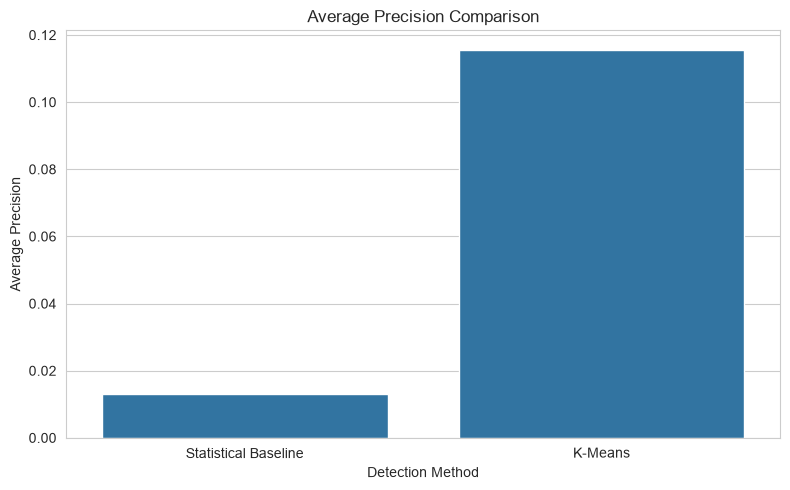

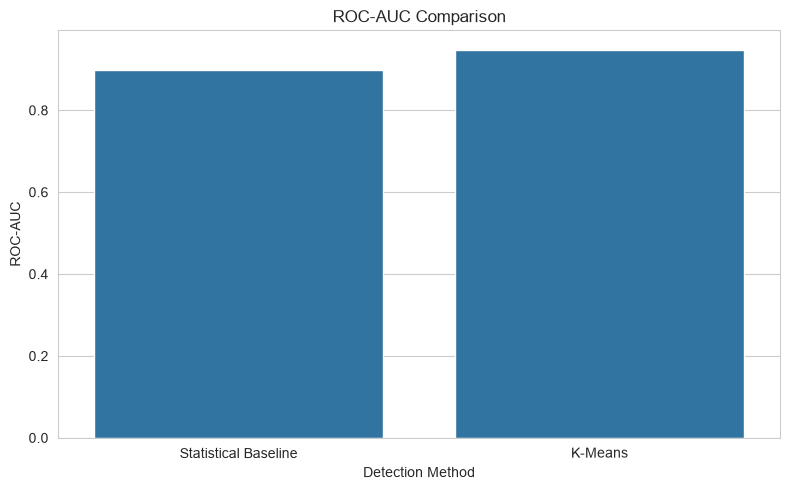

In [31]:
# Create a comparison of the two anomaly detection approaches
baseline_comparison = pd.DataFrame({
    'Method': ['Statistical Baseline', 'K-Means'],
    'Average Precision': [statistical_ap, kmeans_ap],
    'ROC-AUC': [statistical_roc, kmeans_roc]
})

# Display the comparison table
display(baseline_comparison.round(4))

# Plot Average Precision comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=baseline_comparison,
    x='Method',
    y='Average Precision'
)

plt.title('Average Precision Comparison')
plt.ylabel('Average Precision')
plt.xlabel('Detection Method')
plt.tight_layout()
plt.show()

# Plot ROC-AUC comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=baseline_comparison,
    x='Method',
    y='ROC-AUC'
)

plt.title('ROC-AUC Comparison')
plt.ylabel('ROC-AUC')
plt.xlabel('Detection Method')
plt.tight_layout()
plt.show()

## 6. Class-Based Anomaly Detection
Random Forest was selected because it can learn complex relationships between transaction features and fraud labels using multiple decision trees.

The model was trained on labelled data using `balanced_subsample` class weighting to address class imbalance. Predicted fraud probabilities were used as anomaly scores, with higher scores indicating greater suspicion. The testing data was reserved for evaluating performance on unseen transactions.

In [32]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Initialise the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced_subsample',
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Train the model using the training features and labels
rf_model.fit(X_train, y_train)

print("Random Forest model training completed.")

Random Forest model training completed.


In [33]:
# Predicting the probability of each testing transaction being fraudulent
rf_scores = rf_model.predict_proba(X_test)[:, 1]

# Display the highest predicted fraud probabilities
rf_top_scores = pd.Series(
    rf_scores,
    index=X_test.index
).sort_values(ascending=False)

print("Top 10 transactions with the highest predicted fraud probabilities:")
print(rf_top_scores.head(10))

Top 10 transactions with the highest predicted fraud probabilities:
152223    0.999995
42769     0.999976
42936     0.999938
42009     0.996590
15476     0.996589
31002     0.996576
43160     0.993275
178208    0.993257
6734      0.993256
43204     0.993214
dtype: float64


In [34]:
# Calculating Average Precision
rf_ap = average_precision_score(
    y_test,
    rf_scores
)

# Calculate ROC-AUC
rf_roc = roc_auc_score(
    y_test,
    rf_scores
)

# Display the evaluation results
print("RANDOM FOREST CLASSIFICATION RESULTS")
print("--------------------------------")
print(f"Average Precision (PR-AUC): {rf_ap:.4f}")
print(f"ROC-AUC: {rf_roc:.4f}")

RANDOM FOREST CLASSIFICATION RESULTS
--------------------------------
Average Precision (PR-AUC): 0.8264
ROC-AUC: 0.9504


In [35]:
# Combine predicted fraud probabilities with actual labels
rf_results = pd.DataFrame({
    'Fraud_Probability': rf_scores,
    'Actual_Class': y_test.to_numpy()
}, index=y_test.index)

# Sort transactions by predicted fraud probability
rf_results = rf_results.sort_values(
    by='Fraud_Probability',
    ascending=False
)

# Evaluate the highest-ranked transactions
k_values = [50, 100, 200, 500]

for k in k_values:

    # Select the top K transactions
    top_k = rf_results.head(k)

    # Count actual fraudulent transactions
    fraud_found = top_k['Actual_Class'].sum()

    # Calculate precision and recall
    precision_k = fraud_found / k
    recall_k = fraud_found / y_test.sum()

    print(f"\nTop {k} transactions")
    print("Fraudulent transactions found:", int(fraud_found))
    print(f"Precision@{k}: {precision_k:.4f}")
    print(f"Recall@{k}: {recall_k:.4f}")


Top 50 transactions
Fraudulent transactions found: 49
Precision@50: 0.9800
Recall@50: 0.3451

Top 100 transactions
Fraudulent transactions found: 97
Precision@100: 0.9700
Recall@100: 0.6831

Top 200 transactions
Fraudulent transactions found: 119
Precision@200: 0.5950
Recall@200: 0.8380

Top 500 transactions
Fraudulent transactions found: 123
Precision@500: 0.2460
Recall@500: 0.8662


### 6.1 Random Forest Results and Interpretation
Random Forest achieved an Average Precision of 0.8264 and ROC-AUC of 0.9504, outperforming both the statistical baseline and K-Means clustering. It was particularly effective at ranking suspicious transactions.

Among the top 50 transactions, 49 were fraudulent (98.00% precision and 34.51% recall). In the top 100, it identified 97 fraud cases (97.00% precision and 68.31% recall). Among the top 500, it detected 123 of the 142 fraud cases, achieving 86.62% recall.

These results show that Random Forest was the most effective approach for prioritising fraudulent transactions. Its performance highlights the value of learning complex fraud patterns, although results should be considered alongside the limitations of the dataset and labelled data.

In [36]:
# Creating a comparison table for all three approaches
model_comparison = pd.DataFrame({
    'Method': [
        'Statistical Baseline',
        'K-Means',
        'Random Forest'
    ],
    'Average Precision': [
        statistical_ap,
        kmeans_ap,
        rf_ap
    ],
    'ROC-AUC': [
        statistical_roc,
        kmeans_roc,
        rf_roc
    ]
})

# Display the comparison
print("OVERALL MODEL PERFORMANCE COMPARISON")
display(model_comparison.round(4))

OVERALL MODEL PERFORMANCE COMPARISON


,Method,Average Precision,ROC-AUC
0,Statistical Baseline,0.0129,0.8985
1,K-Means,0.1156,0.9475
2,Random Forest,0.8264,0.9504


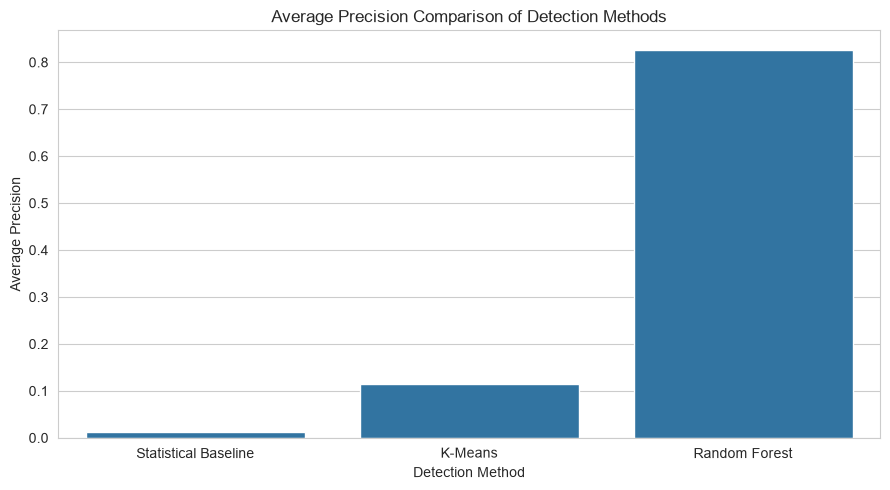

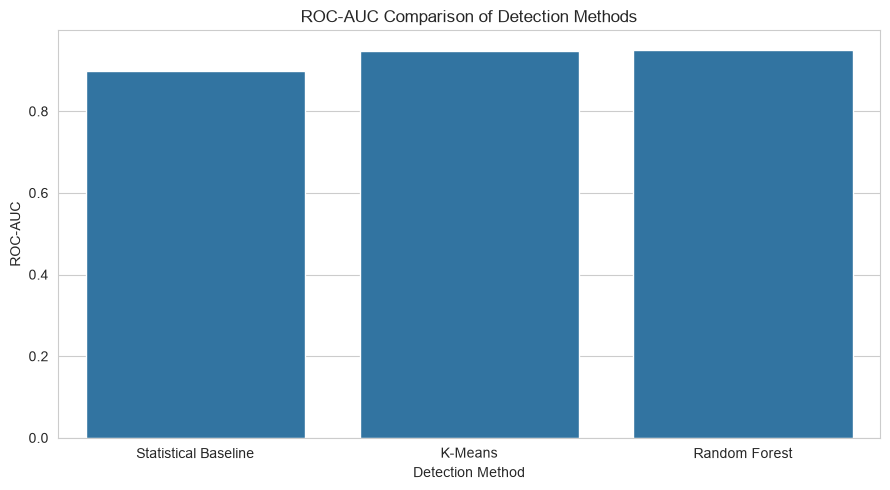

In [37]:
# Plot Average Precision comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Method',
    y='Average Precision'
)

plt.title('Average Precision Comparison of Detection Methods')
plt.xlabel('Detection Method')
plt.ylabel('Average Precision')
plt.tight_layout()
plt.show()


# Plot ROC-AUC comparison
plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x='Method',
    y='ROC-AUC'
)

plt.title('ROC-AUC Comparison of Detection Methods')
plt.xlabel('Detection Method')
plt.ylabel('ROC-AUC')
plt.tight_layout()
plt.show()

In [38]:
# Define investigation capacities
k_values = [50, 100, 200, 500]

# Store results for each approach
ranking_comparison = []

# Evaluate each method
methods = {
    'Statistical Baseline': statistical_results,
    'K-Means': kmeans_results,
    'Random Forest': rf_results
}

for method_name, results in methods.items():

    for k in k_values:

        # Select the top K transactions
        top_k = results.head(k)

        # Count fraudulent transactions
        fraud_found = top_k['Actual_Class'].sum()

        # Calculate precision and recall
        precision_k = fraud_found / k
        recall_k = fraud_found / y_test.sum()

        ranking_comparison.append({
            'Method': method_name,
            'Investigation Capacity': k,
            'Fraud Found': int(fraud_found),
            'Precision': precision_k,
            'Recall': recall_k
        })

# Convert results into a DataFrame
ranking_comparison = pd.DataFrame(ranking_comparison)

# Display the comparison
display(ranking_comparison.round(4))

,Method,Investigation Capacity,Fraud Found,Precision,Recall
0,Statistical Baseline,50,0,0.000,0.0000
1,Statistical Baseline,100,0,0.000,0.0000
2,Statistical Baseline,200,0,0.000,0.0000
3,Statistical Baseline,500,4,0.008,0.0282
4,K-Means,50,16,0.320,0.1127
5,K-Means,100,25,0.250,0.1761
6,K-Means,200,34,0.170,0.2394
7,K-Means,500,55,0.110,0.3873
8,Random Forest,50,49,0.980,0.3451
9,Random Forest,100,97,0.970,0.6831


In [39]:
# Generate fraud probabilities for the training data
rf_train_scores = rf_model.predict_proba(X_train)[:, 1]

# Calculate Average Precision on training data
rf_train_ap = average_precision_score(
    y_train,
    rf_train_scores
)

# Calculate Average Precision on testing data
rf_test_ap = average_precision_score(
    y_test,
    rf_scores
)

# Display the results
print("RANDOM FOREST OVERFITTING CHECK")
print("--------------------------------")
print(f"Training Average Precision: {rf_train_ap:.4f}")
print(f"Testing Average Precision:  {rf_test_ap:.4f}")

RANDOM FOREST OVERFITTING CHECK
--------------------------------
Training Average Precision: 0.9966
Testing Average Precision:  0.8264


## 7. Comparison of Detection Methods
The three methods produced different results. The statistical baseline achieved an Average Precision of 0.0129 and ROC-AUC of 0.8985, while K-Means achieved 0.1156 and 0.9475. Random Forest performed best, with an Average Precision of 0.8264 and ROC-AUC of 0.9504.

Random Forest also performed best in ranking, identifying 49 fraudulent transactions among the top 50 (98.00% precision) and achieving 68.31% recall within the top 100. K-Means identified 25 fraud cases in the top 100, while the statistical baseline identified none. Overall, Random Forest was the most effective, followed by K-Means.

### 7.1 Overfitting Assessment

Random Forest achieved a training Average Precision of 0.9966 compared with 0.8264 on testing data, suggesting some overfitting.

However, its testing performance remained strong, indicating reasonable generalisation to unseen transactions, although further robustness assessment is needed.

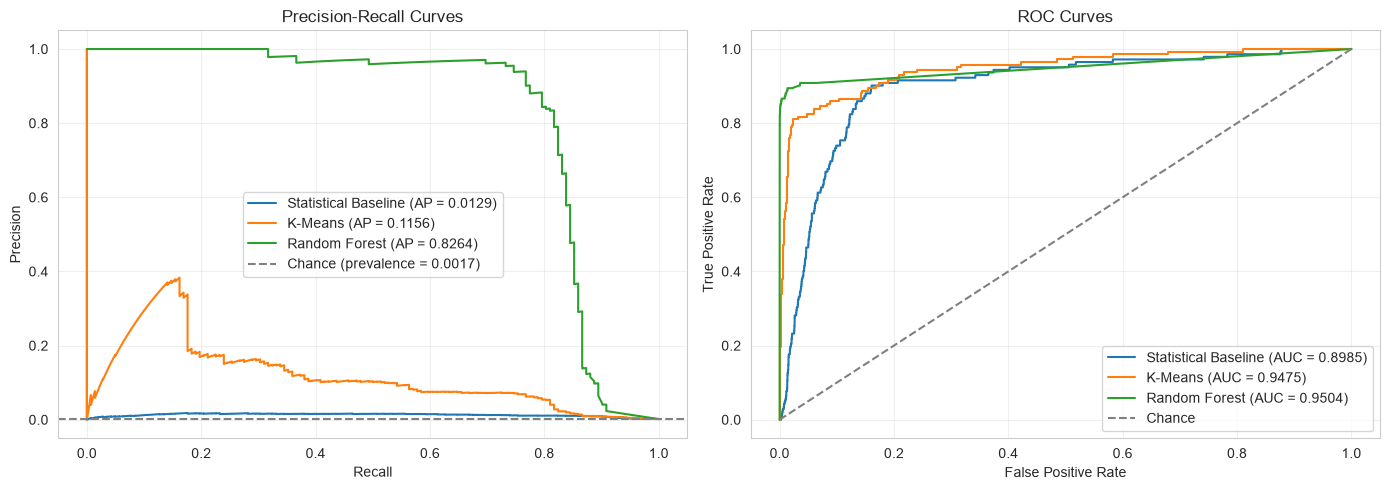

In [40]:
# Importing curve-generation utilities
from sklearn.metrics import precision_recall_curve, roc_curve

# Creating a side-by-side figure for PR and ROC curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Store the three methods with their scores and labels
curve_methods = {
    'Statistical Baseline': (statistical_scores, y_test),
    'K-Means': (kmeans_scores, y_test),
    'Random Forest': (rf_scores, y_test)
}

# Plot the Precision-Recall curves
for method_name, (scores, labels) in curve_methods.items():
    precision, recall, _ = precision_recall_curve(labels, scores)
    ap = average_precision_score(labels, scores)
    axes[0].plot(recall, precision, label=f'{method_name} (AP = {ap:.4f})')

# Add a baseline representing the fraud prevalence
fraud_rate = y_test.mean()
axes[0].axhline(
    y=fraud_rate,
    color='grey',
    linestyle='--',
    label=f'Chance (prevalence = {fraud_rate:.4f})'
)

axes[0].set_title('Precision-Recall Curves')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot the ROC curves
for method_name, (scores, labels) in curve_methods.items():
    fpr, tpr, _ = roc_curve(labels, scores)
    auc = roc_auc_score(labels, scores)
    axes[1].plot(fpr, tpr, label=f'{method_name} (AUC = {auc:.4f})')

# Add the diagonal chance line
axes[1].plot([0, 1], [0, 1], color='grey', linestyle='--', label='Chance')

axes[1].set_title('ROC Curves')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

The PR curves show that Random Forest maintains high precision across most recall levels, while the statistical baseline collapses to near-zero precision almost immediately — even though its ROC-AUC is relatively high. This gap illustrates why ROC-AUC can be misleading under extreme class imbalance and why PR-AUC is the more informative metric for ranking-based fraud detection.

## 8. Robustness and Sensitivity Analysis
Sensitivity analysis was conducted by varying the Random Forest `min_samples_leaf` parameter to assess its effect on fraud detection and potential overfitting. Average Precision, ROC-AUC, and ranking performance were compared to determine the model's consistency across different settings.

In [41]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Define the minimum leaf sizes to investigate 
leaf_sizes = [1, 2, 5, 10]

# Store the results
sensitivity_results = []

# Train and evaluate a model for each leaf size
for leaf_size in leaf_sizes:

    print(f"Testing min_samples_leaf = {leaf_size}")

    # Initialise the model
    model = RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced_subsample',
        min_samples_leaf=leaf_size,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )

    # Train using the training data
    model.fit(X_train, y_train)

    # Generate training and testing fraud probabilities
    train_scores = model.predict_proba(X_train)[:, 1]
    test_scores = model.predict_proba(X_test)[:, 1]

    # Calculate Average Precision
    train_ap = average_precision_score(y_train, train_scores)
    test_ap = average_precision_score(y_test, test_scores)

    # Calculate ROC-AUC
    test_roc = roc_auc_score(y_test, test_scores)

    # Rank testing transactions
    top_100_indices = np.argsort(test_scores)[::-1][:100]

    # Count fraudulent transactions among the top 100
    fraud_found = y_test.iloc[top_100_indices].sum()

    # Calculate precision and recall at 100
    precision_100 = fraud_found / 100
    recall_100 = fraud_found / y_test.sum()

    # Store the results
    sensitivity_results.append({
        'Min Samples Leaf': leaf_size,
        'Training AP': train_ap,
        'Testing AP': test_ap,
        'Testing ROC-AUC': test_roc,
        'Fraud Found Top 100': int(fraud_found),
        'Precision@100': precision_100,
        'Recall@100': recall_100
    })

# Convert results into a DataFrame
sensitivity_results = pd.DataFrame(sensitivity_results)

# Display the results
display(sensitivity_results.round(4))

Testing min_samples_leaf = 1
Testing min_samples_leaf = 2
Testing min_samples_leaf = 5
Testing min_samples_leaf = 10


,Min Samples Leaf,Training AP,Testing AP,Testing ROC-AUC,Fraud Found Top 100,Precision@100,Recall@100
0,1,1.0000,0.8223,0.9513,97,0.97,0.6831
1,2,0.9966,0.8264,0.9504,97,0.97,0.6831
2,5,0.9857,0.8197,0.9646,96,0.96,0.6761
3,10,0.9662,0.8069,0.9680,93,0.93,0.6549


### 8.1 Sensitivity Analysis Results
The sensitivity analysis showed that the Random Forest model maintained strong performance across different `min_samples_leaf` settings. A value of 2 achieved the highest testing Average Precision of 0.8264 and identified 97 fraudulent transactions among the top 100 ranked transactions. Increasing the leaf size reduced training performance, suggesting lower model complexity and some reduction in overfitting. However, this also resulted in a gradual decline in Average Precision and top-100 fraud detection performance. Although a leaf size of 10 achieved the highest ROC-AUC of 0.9680, its Average Precision decreased to 0.8069.
Therefore, `min_samples_leaf=2` was retained because it provided the best Average Precision and maintained the strongest top-100 investigation performance. Overall, the results indicate that the model's performance was reasonably consistent across the tested configurations.

In [42]:
# Import cross-validation utilities
from sklearn.model_selection import StratifiedKFold

# Define a stratified 5-fold splitter
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store per-fold AP and ROC-AUC
cv_ap_scores = []
cv_roc_scores = []

# Refit the model on each fold and evaluate on the held-out fold
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):

    # Split the training data into fold-train and fold-validation
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Fit a fresh model with the same hyperparameters
    fold_model = RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced_subsample',
        min_samples_leaf=2,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )
    fold_model.fit(X_fold_train, y_fold_train)

    # Generate probabilities on the held-out fold
    fold_scores = fold_model.predict_proba(X_fold_val)[:, 1]

    # Record AP and ROC-AUC
    cv_ap_scores.append(average_precision_score(y_fold_val, fold_scores))
    cv_roc_scores.append(roc_auc_score(y_fold_val, fold_scores))

    print(f'Fold {fold} | AP = {cv_ap_scores[-1]:.4f} | ROC-AUC = {cv_roc_scores[-1]:.4f}')

# Summarise across folds
print('\nCross-Validation Summary (Random Forest)')
print('----------------------------------------')
print(f'AP     mean = {np.mean(cv_ap_scores):.4f}  std = {np.std(cv_ap_scores):.4f}')
print(f'ROC    mean = {np.mean(cv_roc_scores):.4f}  std = {np.std(cv_roc_scores):.4f}')

Fold 1 | AP = 0.8159 | ROC-AUC = 0.9669
Fold 2 | AP = 0.8609 | ROC-AUC = 0.9745
Fold 3 | AP = 0.8109 | ROC-AUC = 0.9663
Fold 4 | AP = 0.8738 | ROC-AUC = 0.9822
Fold 5 | AP = 0.8611 | ROC-AUC = 0.9503

Cross-Validation Summary (Random Forest)
----------------------------------------
AP     mean = 0.8445  std = 0.0259
ROC    mean = 0.9680  std = 0.0106


The 5-fold cross-validation was performed on the training portion only, with the testing portion held out throughout. This avoids leaking test information into model selection and provides an honest, out-of-fold estimate of how consistently the Random Forest generalises across different subsets of the labelled data.

In [43]:
# Sort the cleaned dataset chronologically by Time
df_time_sorted = df_clean.sort_values('Time').reset_index(drop=True)

# Use the first 70% of the observation period for training
split_row = int(len(df_time_sorted) * 0.70)

train_time = df_time_sorted.iloc[:split_row]
test_time = df_time_sorted.iloc[split_row:]

# Build feature matrices and labels using the same feature columns
X_train_t = train_time[feature_columns]
y_train_t = train_time['Class']
X_test_t = test_time[feature_columns]
y_test_t = test_time['Class']

# Report the split boundaries and class balance
print('Time-based split summary')
print('------------------------')
print(f'Train rows: {len(X_train_t):,} | Frauds: {int(y_train_t.sum())} ({y_train_t.mean()*100:.4f}%)')
print(f'Test  rows: {len(X_test_t):,} | Frauds: {int(y_test_t.sum())} ({y_test_t.mean()*100:.4f}%)')
print(f'Train Time range: {train_time["Time"].min():.0f} – {train_time["Time"].max():.0f} s')
print(f'Test  Time range: {test_time["Time"].min():.0f} – {test_time["Time"].max():.0f} s')

# Fit a fresh Random Forest on the chronological training portion
time_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced_subsample',
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
time_model.fit(X_train_t, y_train_t)

# Score the chronological test portion
time_scores = time_model.predict_proba(X_test_t)[:, 1]

# Compute the headline metrics
time_ap = average_precision_score(y_test_t, time_scores)
time_roc = roc_auc_score(y_test_t, time_scores)

print('\nTime-based Evaluation (Random Forest)')
print('--------------------------------------')
print(f'Average Precision (PR-AUC): {time_ap:.4f}')
print(f'ROC-AUC: {time_roc:.4f}')

# Evaluate ranking performance at the same capacities
for k in [50, 100, 200, 500]:
    top_k_labels = y_test_t.iloc[np.argsort(time_scores)[::-1][:k]]
    fraud_found = int(top_k_labels.sum())
    print(f'Top {k:>3}: frauds = {fraud_found:>3} | '
          f'precision = {fraud_found/k:.4f} | '
          f'recall = {fraud_found/y_test_t.sum():.4f}')

Time-based split summary
------------------------
Train rows: 198,608 | Frauds: 366 (0.1843%)
Test  rows: 85,118 | Frauds: 107 (0.1257%)
Train Time range: 0 – 132906 s
Test  Time range: 132906 – 172792 s

Time-based Evaluation (Random Forest)
--------------------------------------
Average Precision (PR-AUC): 0.8234
ROC-AUC: 0.9489
Top  50: frauds =  50 | precision = 1.0000 | recall = 0.4673
Top 100: frauds =  84 | precision = 0.8400 | recall = 0.7850
Top 200: frauds =  89 | precision = 0.4450 | recall = 0.8318
Top 500: frauds =  93 | precision = 0.1860 | recall = 0.8692


For the chronological evaluation, the Random Forest hyperparameters were fixed to the values selected during the earlier random-split cross-validation and were not re-tuned on the chronological test portion. This preserves the test portion as a genuinely unseen set, so the result reflects forward generalisation rather than test-set fitting. Performance was essentially unchanged (AP = 0.8234 vs. 0.8264 for the random split), which is consistent with the fraud patterns in this two-day window being stationary.

## 9. Understanding the Difference Between Anomalies and Fraud
An unusual transaction is not necessarily fraudulent. It may differ from normal customer behaviour due to legitimate activities, such as large purchases, travelling, or transactions at unfamiliar times.

Anomaly detection identifies unusual patterns but does not confirm fraud. Therefore, flagged transactions should be investigated rather than automatically classified as fraudulent, since false alerts may inconvenience customers and reduce trust.

In this project, models were evaluated using known fraud labels to assess how well they ranked fraudulent transactions. In practice, their predictions should help investigators prioritise transactions for review, with final decisions based on further checks and human judgement.

## 10. Limitations of the Analysis
The analysis has several limitations. The dataset covers only two days in September 2013, limiting its representation of current transaction patterns. Most features (V1–V28) are anonymised PCA-derived variables, making interpretation difficult. The severe class imbalance also makes fraud detection challenging.

Additionally, the random train-test split does not assess performance on future transactions. Random Forest showed some overfitting, while removing duplicate records may have excluded genuine repeated transactions.

These limitations should be considered when interpreting the findings and applying the models in real-world fraud detection.

In [44]:
# Extract feature importance scores from the trained Random Forest model
feature_importance = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': rf_model.feature_importances_
})

# Arrange features from most to least important
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display the 15 most important features
display(feature_importance.head(15).round(4))

,Feature,Importance
14,V14,0.1705
10,V10,0.1274
4,V4,0.1123
12,V12,0.1058
17,V17,0.0820
3,V3,0.0599
16,V16,0.0525
11,V11,0.0519
7,V7,0.0310
2,V2,0.0279


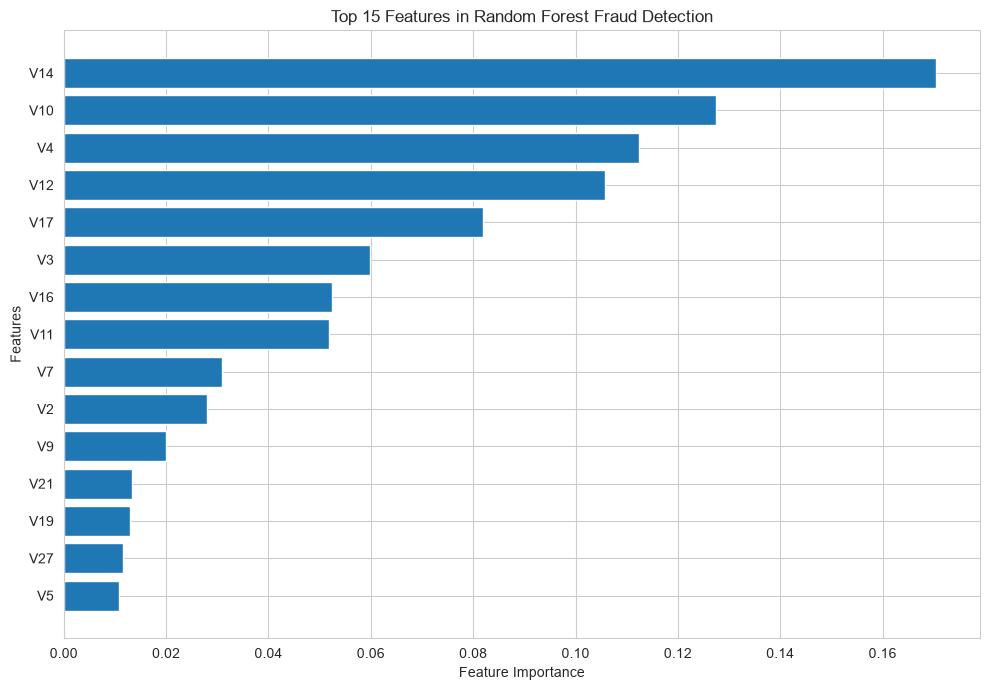

In [45]:
# Plot the 15 most important features

top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 15 Features in Random Forest Fraud Detection')

plt.tight_layout()
plt.show()

## 11. Interpretation of Feature Importance
The feature importance analysis showed that V14 was the most influential variable in the Random Forest model, with an importance score of 0.1705. This was followed by V10 (0.1274), V4 (0.1123), V12 (0.1058) and V17 (0.0820). These five features contributed substantially to the model's predictions compared with the other variables.

The results suggest that the anonymised PCA-derived features provided important information for distinguishing fraudulent from legitimate transactions. However, their original meanings cannot be established because the dataset does not provide their direct interpretations. Feature importance also indicates predictive contribution rather than causation.

In [46]:
# Import permutation importance
from sklearn.inspection import permutation_importance

# Compute permutation importance on the test set
# (n_repeats=10 balances stability against runtime)
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='average_precision',
    n_jobs=-1
)

# Assemble a comparison table
perm_df = pd.DataFrame({
    'Feature': feature_columns,
    'Impurity_Importance': rf_model.feature_importances_,
    'Permutation_Mean': perm_result.importances_mean,
    'Permutation_Std': perm_result.importances_std
}).sort_values('Permutation_Mean', ascending=False)

# Display the top 15 by permutation importance
display(perm_df.head(15).round(4))

,Feature,Impurity_Importance,Permutation_Mean,Permutation_Std
4,V4,0.1123,0.0460,0.0080
11,V11,0.0519,0.0223,0.0121
14,V14,0.1705,0.0192,0.0026
3,V3,0.0599,0.0153,0.0071
28,V28,0.0073,0.0145,0.0024
9,V9,0.0199,0.0128,0.0054
18,V18,0.0099,0.0111,0.0024
7,V7,0.0310,0.0111,0.0039
26,V26,0.0079,0.0109,0.0020
16,V16,0.0525,0.0101,0.0058


## Conclusion and Recommendations 
This project evaluated statistical, clustering-based and classification-based methods for detecting potentially fraudulent credit card transactions. Fraud cases represented approximately 0.17% of the dataset after duplicate removal.

Random Forest performed best, achieving an Average Precision of 0.8264 and ROC-AUC of 0.9504. It identified 97 fraudulent transactions among the top 100 ranked transactions, achieving 97% precision and 68.31% recall. This outperformed the Robust Z-score baseline (0.0129) and MiniBatch K-Means (0.1156).

Sensitivity analysis showed that Random Forest maintained strong performance across different settings. Feature importance analysis identified V14, V10, V4, V12 and V17 as the most influential features, although their anonymised nature limits interpretation.

Overall, Random Forest is the preferred approach for prioritising suspicious transactions. Its predictions should support investigations rather than automatically classify transactions as fraudulent. Further testing with recent data and time-based validation is recommended before real-world application.